# LeNet-5 from Scratch with Keras
## Handwritten Digit Recognition on MNIST

This notebook is designed for classroom teaching. We will:

1. Understand the LeNet-5 architecture.
2. Build LeNet-5 from scratch using Keras.
3. Display its architecture as a block diagram.
4. Train the model on the MNIST handwritten-digit dataset.
5. Save and reload the trained model as a **pretrained LeNet model**.
6. Use it to recognize digits from MNIST and from an uploaded image.

> **Colab tip:** Select **Runtime → Change runtime type → T4 GPU** for faster training. A CPU also works.

## LeNet-5 Architecture at a Glance

<p align="center">
  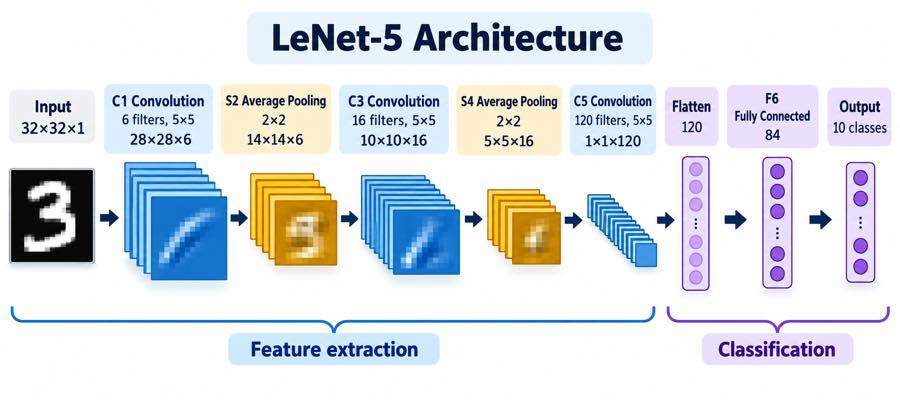
</p>

*The convolution and pooling stages extract increasingly useful visual features; the final fully connected stages classify the digit.*

## Essential LeNet-5 Theory

**Background**

- LeNet-5 is an early and highly influential **convolutional neural network (CNN)** for recognizing handwritten and machine-printed characters.
- It was described by **Yann LeCun, Léon Bottou, Yoshua Bengio, and Patrick Haffner** in their 1998 paper on document recognition.
- Its most important idea is **end-to-end learning**: the network learns useful image features and the final classifier directly from labeled examples.
- The name *LeNet-5* comes from a series of LeNet models; it does not mean that the network contains only five Keras layers.

**Core CNN ideas demonstrated by LeNet**

- **Local receptive fields:** a neuron examines a small region of the previous feature map instead of the complete image.
- **Weight sharing:** the same convolution filter slides across the image, so one learned pattern can be detected in many positions while using fewer parameters.
- **Feature hierarchy:** early layers learn simple patterns such as edges; later layers combine them into curves, strokes, and digit-specific shapes.
- **Subsampling/pooling:** spatial dimensions are reduced, lowering computation and making the representation less sensitive to small shifts in the digit.
- **Backpropagation:** prediction error is propagated backward so that all trainable weights can be improved using gradient-based optimization.

**How data moves through this notebook's network**

- MNIST images are originally **28 × 28 × 1**. A 2-pixel border is added on all sides to produce the **32 × 32 × 1** input expected by LeNet-5.
- **C1:** six 5 × 5 filters convert the input into six 28 × 28 feature maps.
- **S2:** 2 × 2 average pooling halves the width and height to 14 × 14.
- **C3 and S4:** sixteen feature maps are learned and then reduced to 5 × 5.
- **C5:** 120 filters cover the complete 5 × 5 spatial area, producing 120 learned values.
- **F6:** 84 neurons combine those features. The final 10-neuron softmax layer produces one probability for each digit from 0 to 9.
- For a valid convolution with stride 1, the output width or height is **N − F + 1**, where N is the input size and F is the filter size.

**Why this implementation is slightly modernized**

- The historical LeNet-5 used carefully designed partial connections in C3 and a different output classifier. This classroom version uses standard fully connected Keras convolutions and a **softmax** output so that the code remains short and easy to understand.
- It keeps the classic **tanh activations** and **average pooling**. Many modern CNNs instead use ReLU, max pooling, batch normalization, and deeper architectures.
- The model is compact—this implementation has only **61,706 trainable parameters**—which makes it fast enough for a classroom demonstration.

**Strengths and limitations**

- **Strengths:** simple, fast, interpretable layer flow, and very effective for small grayscale images such as MNIST digits.
- **Limitations:** designed for small centered images; it is much less suitable than modern CNNs for high-resolution color images, large viewpoint changes, or complex natural scenes.
- A high MNIST test accuracy does not automatically mean the model will recognize every phone photo or hand-drawn digit; preprocessing and similarity to the training data still matter.

**Further reading:** [Original LeNet-5 paper and resources](https://leon.bottou.org/papers/lecun-98h) · [TensorFlow Conv2D documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D) · [TensorFlow AveragePooling2D documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/AveragePooling2D)

## 1. Import the libraries

TensorFlow includes Keras, which gives us simple tools for building and training neural networks.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Make the results more reproducible
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Load and prepare MNIST

MNIST contains 28 × 28 grayscale images of digits from 0 to 9. The original LeNet-5 expects 32 × 32 images, so we add a 2-pixel border on every side. Pixel values are also scaled from 0–255 to 0–1.

In [ ]:
# Download the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale pixel values to the range 0 to 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a 2-pixel border: 28 x 28 becomes 32 x 32
x_train = np.pad(x_train, ((0, 0), (2, 2), (2, 2)), mode="constant")
x_test = np.pad(x_test, ((0, 0), (2, 2), (2, 2)), mode="constant")

# Add the channel dimension: (32, 32) becomes (32, 32, 1)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training data shape:", x_train.shape)
print("Test data shape:    ", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 32, 32, 1)
Test data shape:     (10000, 32, 32, 1)


### View a few training images

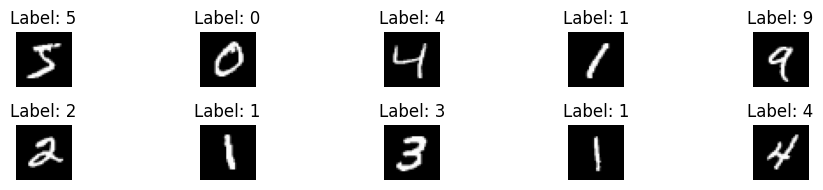

In [ ]:
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. LeNet-5 architecture

| Stage | Layer | Output shape | Purpose |
|---|---|---:|---|
| Input | Image | 32 × 32 × 1 | Grayscale digit |
| C1 | Conv2D: 6 filters, 5 × 5 | 28 × 28 × 6 | Learn simple features |
| S2 | Average Pooling: 2 × 2 | 14 × 14 × 6 | Reduce size |
| C3 | Conv2D: 16 filters, 5 × 5 | 10 × 10 × 16 | Learn richer features |
| S4 | Average Pooling: 2 × 2 | 5 × 5 × 16 | Reduce size |
| C5 | Conv2D: 120 filters, 5 × 5 | 1 × 1 × 120 | Combine all local features |
| F6 | Dense: 84 neurons | 84 | Learn digit-level patterns |
| Output | Dense: 10 neurons | 10 | Probability of each digit |

We use `tanh` and average pooling to stay close to the classic LeNet-5 design.

## 4. Build LeNet-5 from scratch

In [ ]:
def build_lenet5():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 1), name="input_image"),

        # C1: 32x32x1 -> 28x28x6
        layers.Conv2D(6, kernel_size=5, activation="tanh", name="C1_conv"),

        # S2: 28x28x6 -> 14x14x6
        layers.AveragePooling2D(pool_size=2, strides=2, name="S2_pool"),

        # C3: 14x14x6 -> 10x10x16
        layers.Conv2D(16, kernel_size=5, activation="tanh", name="C3_conv"),

        # S4: 10x10x16 -> 5x5x16
        layers.AveragePooling2D(pool_size=2, strides=2, name="S4_pool"),

        # C5: 5x5x16 -> 1x1x120
        layers.Conv2D(120, kernel_size=5, activation="tanh", name="C5_conv"),
        layers.Flatten(name="flatten"),

        # F6 and output layer
        layers.Dense(84, activation="tanh", name="F6_dense"),
        layers.Dense(10, activation="softmax", name="output")
    ], name="LeNet5")
    return model

lenet = build_lenet5()
lenet.summary()

Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ C1_conv (Conv2D)                │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_pool (AveragePooling2D)      │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_conv (Conv2D)                │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_pool (AveragePooling2D)      │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_conv (Conv2D)                │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_dense (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Display the architecture block diagram

`plot_model` reads the Keras model and draws every layer, connection, and tensor shape.

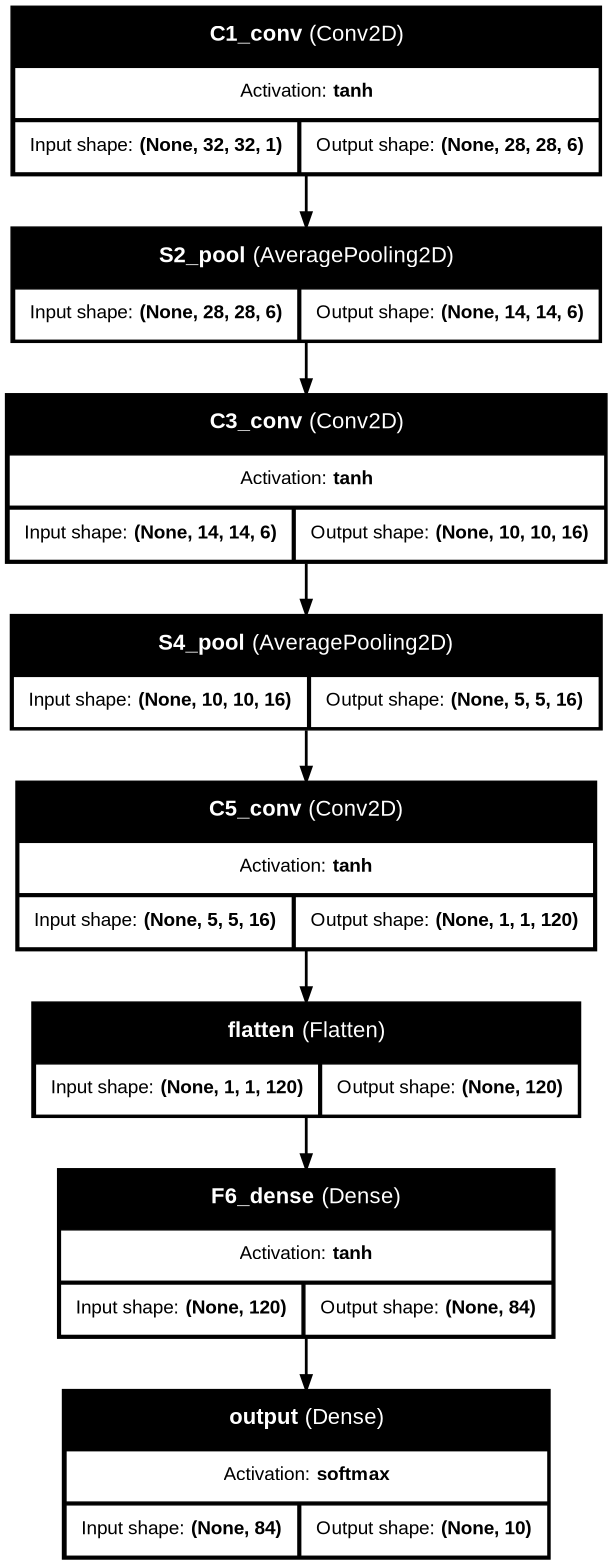

In [ ]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

plot_model(
    lenet,
    to_file="lenet5_block_diagram.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=100
)
display(Image(filename="lenet5_block_diagram.png"))

## 6. Compile and train the model

- **Adam** updates the weights.
- **Sparse categorical cross-entropy** is suitable because labels are integers from 0 to 9.
- **Accuracy** tells us the fraction of correctly classified digits.

In [ ]:
lenet.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = lenet.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8969 - loss: 0.3556 - val_accuracy: 0.9642 - val_loss: 0.1293
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9602 - loss: 0.1310 - val_accuracy: 0.9748 - val_loss: 0.0815
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9744 - loss: 0.0842 - val_accuracy: 0.9782 - val_loss: 0.0667
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9813 - loss: 0.0618 - val_accuracy: 0.9805 - val_loss: 0.0592
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9851 - loss: 0.0478 - val_accuracy: 0.9833 - val_loss: 0.0557


### Plot the learning curves

The training and validation curves help us see whether the model is learning and whether it starts to overfit.

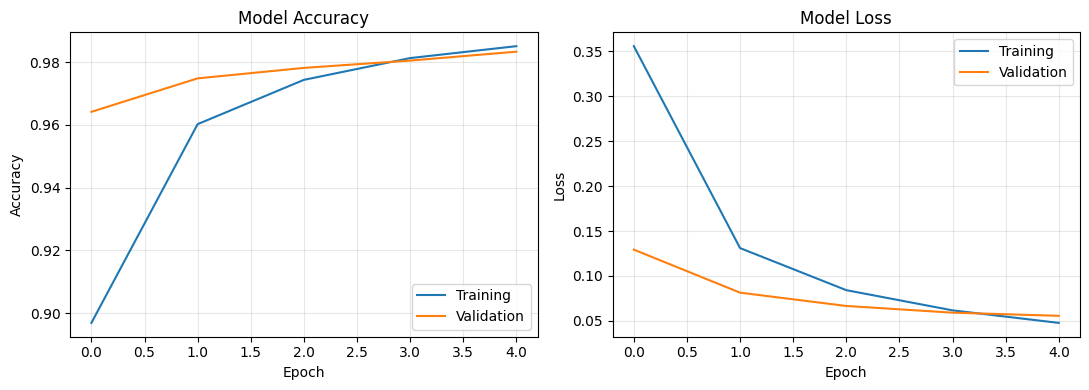

In [ ]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Evaluate on unseen test images

In [ ]:
test_loss, test_accuracy = lenet.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss:     0.0542
Test accuracy: 98.35%


## 8. Save and reload the pretrained LeNet model

A **pretrained model** is simply a model whose weights have already been learned from data. We save our trained network, then load it into a new variable. In a later class, you can upload the saved `.keras` file and skip training.

In [ ]:
# Save the architecture and learned weights in one file
lenet.save("pretrained_lenet_mnist.keras")

# Load it exactly as we would load any pretrained Keras model
pretrained_lenet = keras.models.load_model("pretrained_lenet_mnist.keras")

print("Pretrained LeNet model loaded successfully!")

Pretrained LeNet model loaded successfully!


### Optional: download the trained model

Run this cell in Google Colab if you want to keep the model file for another class.

In [ ]:
# Uncomment these two lines when running in Google Colab:
# from google.colab import files
# files.download("pretrained_lenet_mnist.keras")

## 9. Recognize one handwritten digit

The model returns 10 probabilities. `argmax` selects the digit with the highest probability.

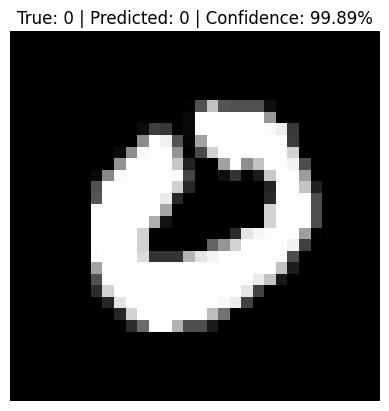

Probability for each digit:
Digit 0: 99.89%
Digit 1: 0.00%
Digit 2: 0.00%
Digit 3: 0.00%
Digit 4: 0.00%
Digit 5: 0.00%
Digit 6: 0.05%
Digit 7: 0.00%
Digit 8: 0.02%
Digit 9: 0.03%


In [ ]:
image_number = 25  # Change this number to try another test image
image = x_test[image_number]
true_label = y_test[image_number]

probabilities = pretrained_lenet.predict(image[np.newaxis, ...], verbose=0)[0]
predicted_label = np.argmax(probabilities)
confidence = probabilities[predicted_label]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"True: {true_label} | Predicted: {predicted_label} | "
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")
plt.show()

print("Probability for each digit:")
for digit, probability in enumerate(probabilities):
    print(f"Digit {digit}: {probability:.2%}")

### Recognize several digits at once

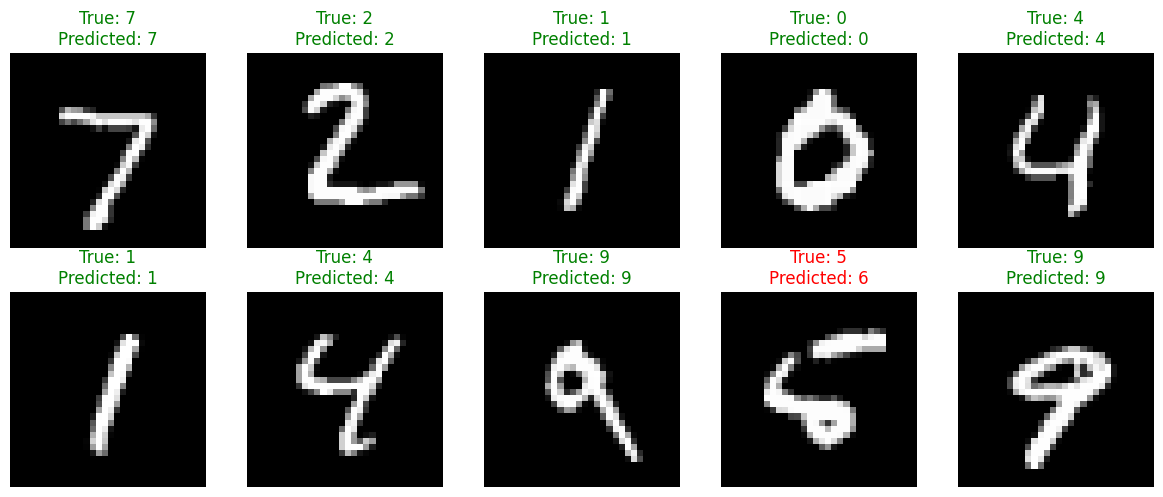

In [ ]:
sample_images = x_test[:10]
sample_predictions = pretrained_lenet.predict(sample_images, verbose=0)
predicted_digits = np.argmax(sample_predictions, axis=1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].squeeze(), cmap="gray")
    color = "green" if predicted_digits[i] == y_test[i] else "red"
    plt.title(
        f"True: {y_test[i]}\nPredicted: {predicted_digits[i]}",
        color=color
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 10. Optional: recognize your own digit image

Create a clear image containing one digit. A dark digit on a light background or a light digit on a dark background will work. The code converts it to the same 32 × 32 format used during training.

> This cell is specifically for Google Colab.

In [ ]:
from google.colab import files
from PIL import Image as PILImage, ImageOps

uploaded = files.upload()
filename = next(iter(uploaded))

# Open the image and convert it to grayscale
custom_image = PILImage.open(filename).convert("L")
custom_image = ImageOps.autocontrast(custom_image)
custom_array = np.array(custom_image)

# MNIST uses a light digit on a dark background
if custom_array.mean() > 127:
    custom_array = 255 - custom_array

# Resize to 28x28, normalize, then pad to 32x32
custom_image = PILImage.fromarray(custom_array).resize((28, 28))
custom_array = np.array(custom_image).astype("float32") / 255.0
custom_array = np.pad(custom_array, ((2, 2), (2, 2)), mode="constant")
custom_array = custom_array[np.newaxis, ..., np.newaxis]

# Predict the digit
custom_probabilities = pretrained_lenet.predict(custom_array, verbose=0)[0]
custom_prediction = np.argmax(custom_probabilities)
custom_confidence = custom_probabilities[custom_prediction]

plt.imshow(custom_array[0].squeeze(), cmap="gray")
plt.title(f"Prediction: {custom_prediction} | Confidence: {custom_confidence:.2%}")
plt.axis("off")
plt.show()

## 11. Key ideas to review

- A convolution layer learns visual features such as edges and curves.
- Pooling reduces the spatial size of feature maps.
- Dense layers combine learned features to classify the digit.
- Softmax converts the final scores into 10 probabilities that sum to 1.
- Training learns the weights; saving those weights gives us a pretrained model.

### Suggested classroom exercises

1. Change `image_number` and inspect different predictions.
2. Replace `tanh` with `relu` and compare accuracy.
3. Replace average pooling with max pooling.
4. Train for fewer or more epochs.
5. Find a test image that the model classifies incorrectly and discuss why.